In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3

df = pd.read_csv(r"C:\Users\HP\nhs_a&e_performance analysis/Data/Processed/April_2025_cleaned.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (199, 22)


,period,org_code,parent_org,org_name,a_e_attendances_type_1,a_e_attendances_type_2,a_e_attendances_other_a_e_department,a_e_attendances_booked_appointments_type_1,a_e_attendances_booked_appointments_type_2,a_e_attendances_booked_appointments_other_department,...,attendances_over_4hrs_other_department,attendances_over_4hrs_booked_appointments_type_1,attendances_over_4hrs_booked_appointments_type_2,attendances_over_4hrs_booked_appointments_other_department,patients_who_have_waited_4_12_hs_from_dta_to_admission,patients_who_have_waited_12_hrs_from_dta_to_admission,emergency_admissions_via_a_e_type_1,emergency_admissions_via_a_e_type_2,emergency_admissions_via_a_e_other_a_e_department,other_emergency_admissions
0,MSitAE-APRIL-2025,NDJ,NHS ENGLAND SOUTH EAST,FIRST COMMUNITY HEALTH AND CARE CIC,0,0,2350,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,MSitAE-APRIL-2025,NTV0B,NHS ENGLAND SOUTH EAST,ASHFORD WALK-IN-CENTRE,0,0,2333,0,0,0,...,49,0,0,0,0,0,0,0,0,0
2,MSitAE-APRIL-2025,NTV0W,NHS ENGLAND SOUTH EAST,WOKING WALK IN CENTRE,0,0,2528,0,0,0,...,58,0,0,0,0,0,0,0,0,0
3,MSitAE-APRIL-2025,Y02615,NHS ENGLAND MIDLANDS,SOUTH BIRMINGHAM GP WALK IN CENTRE,0,0,6628,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,MSitAE-APRIL-2025,AQN04,NHS ENGLAND SOUTH EAST,PHL LYMINGTON UTC,0,0,3297,0,0,12,...,42,0,0,0,0,0,0,0,0,0


In [3]:
df.columns.tolist()

['period',
 'org_code',
 'parent_org',
 'org_name',
 'a_e_attendances_type_1',
 'a_e_attendances_type_2',
 'a_e_attendances_other_a_e_department',
 'a_e_attendances_booked_appointments_type_1',
 'a_e_attendances_booked_appointments_type_2',
 'a_e_attendances_booked_appointments_other_department',
 'attendances_over_4hrs_type_1',
 'attendances_over_4hrs_type_2',
 'attendances_over_4hrs_other_department',
 'attendances_over_4hrs_booked_appointments_type_1',
 'attendances_over_4hrs_booked_appointments_type_2',
 'attendances_over_4hrs_booked_appointments_other_department',
 'patients_who_have_waited_4_12_hs_from_dta_to_admission',
 'patients_who_have_waited_12_hrs_from_dta_to_admission',
 'emergency_admissions_via_a_e_type_1',
 'emergency_admissions_via_a_e_type_2',
 'emergency_admissions_via_a_e_other_a_e_department',
 'other_emergency_admissions']

In [6]:
#create a small dataset with only the columns we need

kpi = df[
["org_code", "org_name", "a_e_attendances_type_1", "attendances_over_4hrs_type_1"]
].copy()

In [10]:
##rename the columns for convinience

kpi.columns = ["org_code", "org_name", "total_attendances", "over_4hrs"]

In [11]:
##calculate attendances within 4 hours

kpi["within_4hrs"] = (kpi["total_attendances"] - kpi["over_4hrs"])

In [12]:
##calculate four hour performance percentage

kpi["within_4hrs_pct"] = (
    kpi["within_4hrs"] / kpi["total_attendances"]
) * 100

In [13]:
kpi.head(20)

,org_code,org_name,total_attendances,over_4hrs,within_4hrs,within_4hrs_pct
0,NDJ,FIRST COMMUNITY HEALTH AND CARE CIC,0,0,0,NaN
1,NTV0B,ASHFORD WALK-IN-CENTRE,0,0,0,NaN
2,NTV0W,WOKING WALK IN CENTRE,0,0,0,NaN
3,Y02615,SOUTH BIRMINGHAM GP WALK IN CENTRE,0,0,0,NaN
4,AQN04,PHL LYMINGTON UTC,0,0,0,NaN
5,C82038,LATHAM HOUSE MEDICAL PRACTICE,0,0,0,NaN
6,NQTE4,SUMMERFIELD URGENT CARE CENTRE,0,0,0,NaN
7,RBQ,LIVERPOOL HEART AND CHEST HOSPITAL NHS FOUNDAT...,0,0,0,NaN
8,RCD,HARROGATE AND DISTRICT NHS FOUNDATION TRUST,4918,1081,3837,78.019520
9,RJ8,CORNWALL PARTNERSHIP NHS FOUNDATION TRUST,0,0,0,NaN


In [14]:
##calculate overall A&E performance

total_attendances = kpi["total_attendances"].sum()

total_over_4hrs = kpi["over_4hrs"].sum()

total_within_4hrs = (total_attendances - total_over_4hrs)

overall_performance = (total_within_4hrs / total_attendances) * 100

print("Total attendances:", total_attendances)
print("Attendances over 4 hours:", total_over_4hrs)
print("Attendances within 4 hours:", total_within_4hrs)

print("Overall four-hour performance:",round(overall_performance, 2), "%")

Total attendances: 2709918
Attendances over 4 hours: 1089640
Attendances within 4 hours: 1620278
Overall four-hour performance: 59.79 %


In [16]:
##Connecting python to sqlite

conn = sqlite3.connect(r"C:\Users\HP\nhs_a&e_performance analysis/Data/Processed/nhs_ae_analysis.db")

kpi.to_sql("ae_data",conn,
if_exists="replace",index=False)

199

In [17]:
query = """
SELECT *
FROM ae_data
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)

display(result)

,org_code,org_name,total_attendances,over_4hrs,within_4hrs,within_4hrs_pct
0,NDJ,FIRST COMMUNITY HEALTH AND CARE CIC,0,0,0,NaN
1,NTV0B,ASHFORD WALK-IN-CENTRE,0,0,0,NaN
2,NTV0W,WOKING WALK IN CENTRE,0,0,0,NaN
3,Y02615,SOUTH BIRMINGHAM GP WALK IN CENTRE,0,0,0,NaN
4,AQN04,PHL LYMINGTON UTC,0,0,0,NaN
5,C82038,LATHAM HOUSE MEDICAL PRACTICE,0,0,0,NaN
6,NQTE4,SUMMERFIELD URGENT CARE CENTRE,0,0,0,NaN
7,RBQ,LIVERPOOL HEART AND CHEST HOSPITAL NHS FOUNDAT...,0,0,0,NaN
8,RCD,HARROGATE AND DISTRICT NHS FOUNDATION TRUST,4918,1081,3837,78.01952
9,RJ8,CORNWALL PARTNERSHIP NHS FOUNDATION TRUST,0,0,0,NaN


In [18]:
##finding the top 10 providers

query = """
SELECT org_name, total_attendances
FROM ae_data
ORDER BY total_attendances DESC
LIMIT 10;
"""

top_providers = pd.read_sql_query(query, conn)

display(top_providers)

,org_name,total_attendances
0,TOTAL,1354959
1,UNIVERSITY HOSPITALS BIRMINGHAM NHS FOUNDATION...,34366
2,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,29676
3,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,25328
4,BARTS HEALTH NHS TRUST,25265
5,NORTHERN CARE ALLIANCE NHS FOUNDATION TRUST,25192
6,ROYAL FREE LONDON NHS FOUNDATION TRUST,24636
7,MANCHESTER UNIVERSITY NHS FOUNDATION TRUST,24296
8,FRIMLEY HEALTH NHS FOUNDATION TRUST,21751
9,UNIVERSITY HOSPITALS OF LEICESTER NHS TRUST,21293


In [19]:
##calculating four-hour performance by SQL

query = """
SELECT org_name, total_attendances, over_4hrs,
total_attendances - over_4hrs
AS within_4hrs,
ROUND(100.0 * (total_attendances - over_4hrs)/ total_attendances,2) AS within_4hrs_pct

FROM ae_data

ORDER BY within_4hrs_pct DESC;
"""

sql_kpi = pd.read_sql_query(query, conn)

display(sql_kpi.head(10))

,org_name,total_attendances,over_4hrs,within_4hrs,within_4hrs_pct
0,SHEFFIELD CHILDREN'S NHS FOUNDATION TRUST,4162,299,3863,92.82
1,BIRMINGHAM WOMEN'S AND CHILDREN'S NHS FOUNDATI...,4837,479,4358,90.10
2,ALDER HEY CHILDREN'S NHS FOUNDATION TRUST,5674,804,4870,85.83
3,CALDERDALE AND HUDDERSFIELD NHS FOUNDATION TRUST,15871,2746,13125,82.70
4,HOMERTON HEALTHCARE NHS FOUNDATION TRUST,10777,1940,8837,82.00
5,WEST SUFFOLK NHS FOUNDATION TRUST,7602,1570,6032,79.35
6,MAIDSTONE AND TUNBRIDGE WELLS NHS TRUST,17983,3733,14250,79.24
7,HARROGATE AND DISTRICT NHS FOUNDATION TRUST,4918,1081,3837,78.02
8,ST GEORGE'S UNIVERSITY HOSPITALS NHS FOUNDATIO...,8495,1972,6523,76.79
9,CHELSEA AND WESTMINSTER HOSPITAL NHS FOUNDATIO...,18876,4578,14298,75.75


In [20]:
##check total records and providers

query = """
SELECT
COUNT(*) AS total_records,
COUNT(DISTINCT org_code) AS total_providers,
SUM(total_attendances) AS total_attendances
FROM ae_data;
"""

summary = pd.read_sql_query(query, conn)

display(summary)

,total_records,total_providers,total_attendances
0,199,199,2709918


In [21]:
conn.close()

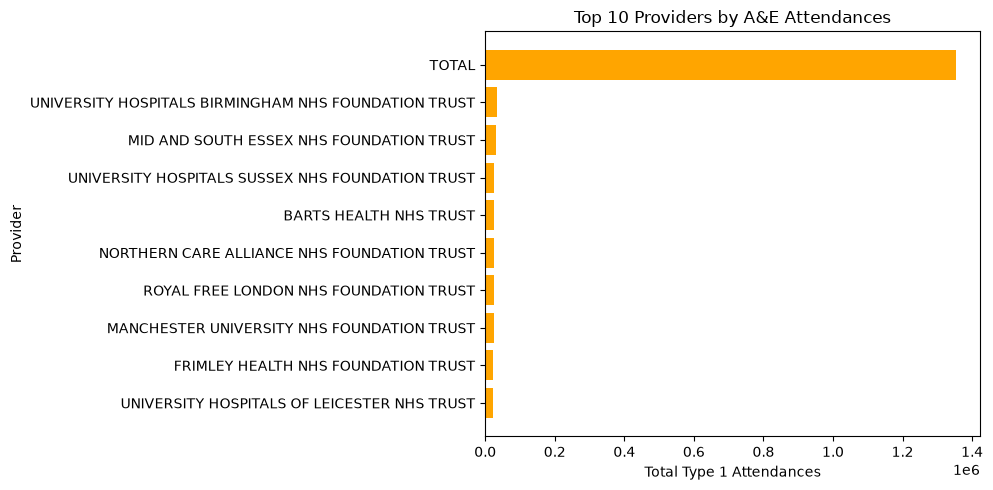

In [23]:
##data visualisation using python
#top ten providers by attendance volume

top_10 = kpi.sort_values("total_attendances", ascending=False).head(10)

plt.figure(figsize=(10, 5))

plt.barh(top_10["org_name"],top_10["total_attendances"], color="orange")

plt.title("Top 10 Providers by A&E Attendances")
plt.xlabel("Total Type 1 Attendances")
plt.ylabel("Provider")

plt.tight_layout()
plt.gca().invert_yaxis()
plt.savefig(r"C:\Users\HP\nhs_a&e_performance analysis/visuals/top_10_attendance.png", dpi=300, bbox_inches="tight")

plt.show()

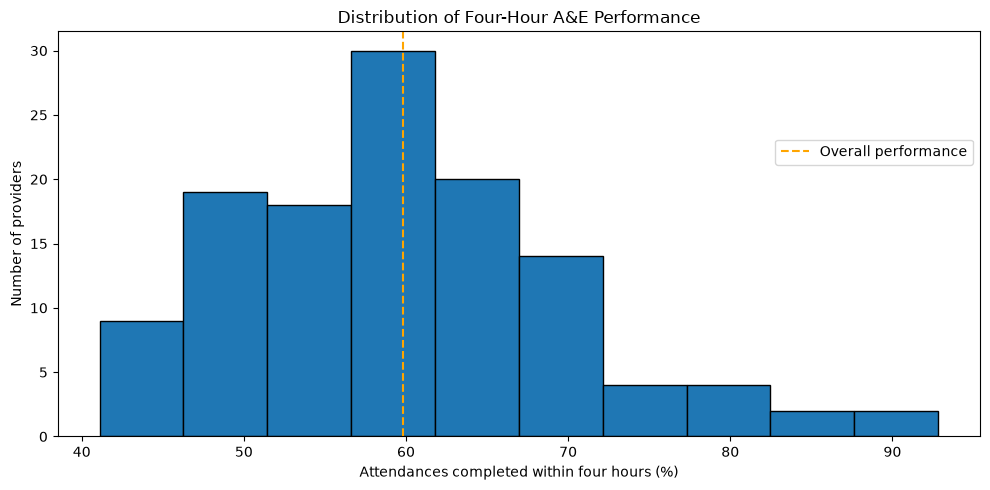

In [24]:
##four-hour performance across providers

plt.figure(figsize=(10, 5))

plt.hist(kpi["within_4hrs_pct"], bins=10, edgecolor="black")

plt.axvline(overall_performance, linestyle="--", label="Overall performance", color="orange")

plt.title("Distribution of Four-Hour A&E Performance")
plt.xlabel("Attendances completed within four hours (%)")
plt.ylabel("Number of providers")

plt.legend(bbox_to_anchor=(1,0.75))
plt.tight_layout()
plt.savefig(r"C:\Users\HP\nhs_a&e_performance analysis/visuals/four_hour_performance.png", dpi=300, bbox_inches="tight")
plt.show()

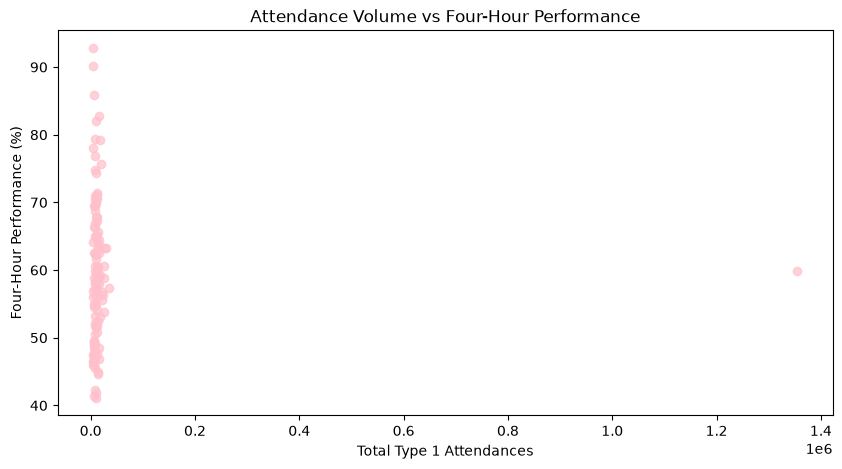

In [25]:
##attendance volume vs. four-hour performance

plt.figure(figsize=(10, 5))

plt.scatter(kpi["total_attendances"], kpi["within_4hrs_pct"], alpha=0.7, color="pink")

plt.title("Attendance Volume vs Four-Hour Performance")
plt.xlabel("Total Type 1 Attendances")
plt.ylabel("Four-Hour Performance (%)")
plt.savefig(r"C:\Users\HP\nhs_a&e_performance analysis/visuals/attendance_vs_four_hour_performance.png", dpi=300, bbox_inches="tight")
plt.show()

## Day 4: Exploratory Data Analysis Findings

### Key Performance Indicators
- Total Type 1 A&E attendances
- Attendances exceeding four hours
- Attendances completed within four hours
- Overall four-hour performance percentage

### SQL Analysis
SQL was used to:
- Retrieve provider-level records.
- Rank providers by attendance volume.
- Calculate four-hour performance.
- Summarise attendance and provider counts.

### Visual Analysis
Three charts were created:
1. Top 10 providers by attendance volume.
2. Distribution of four-hour performance.
3. Attendance volume versus four-hour performance.

### Initial Observations
To be completed using the actual results.

### Limitations
- Analysis covers April 2025 only.
- Provider performance is not adjusted for differences in patient complexity or local circumstances.
- A single month cannot establish performance trends.
- Associations do not establish causation.